## **Daegu Apartment**

[Sumber data bootcamp modul Machine Learning Purwadhika]

## **Contents**

1. Business Problem Understanding
2. Data Understanding
3. Data Preprocessing
4. Modelling
5. Conclusion
6. Recommendation

****

## **Business Problem Understanding**

### Context
Daegu adalah kota di Korea Selatan dengan lahan hunian yang terbatas dan aktivitas bisnis yang padat, sehingga apartemen menjadi salah satu solusi kebutuhan hunian. Unit apartemen ditawarkan oleh perorangan maupun perusahaan, yang menentukan sendiri harga jualnya di sebuah platform. Harga tersebut dipengaruhi oleh faktor internal (misalnya ukuran, umur bangunan, dan fasilitas) maupun faktor eksternal (misalnya jarak ke stasiun subway dan fasilitas di sekitar). Dataset yang digunakan berisi 4.123 baris data unit apartemen di Daegu (2.701 baris setelah data duplikat dibuang).

### Problem Statement
Penjual apartemen, baik perorangan maupun perusahaan, kesulitan menentukan harga jual yang sesuai dengan harga pasar. Kesulitan ini muncul karena harga dipengaruhi banyak faktor sekaligus, seperti ukuran, umur bangunan, fasilitas, dan jarak ke stasiun subway, sehingga pemilik sulit menilai apartemennya sendiri. Akibatnya, harga yang terlalu tinggi membuat unit sulit terjual, sedangkan harga yang terlalu rendah membuat keuntungan tidak maksimal.

### Goals
Tujuan analisis ini adalah membangun model regresi yang dapat memprediksi `SalePrice` (harga jual) berdasarkan karakteristik unit, yaitu tipe lorong, jarak dan stasiun subway terdekat, fasilitas di sekitar dan di dalam apartemen, jumlah universitas di sekitar, parkir basement, tahun dibangun, dan ukuran. Model ini diharapkan menjadi prediction tool yang memberi harga acuan bagi penjual, sehingga harga yang ditetapkan kompetitif bagi pembeli dan tetap menguntungkan bagi penjual.

### Analytic Approach
Analisis dilakukan dalam tiga langkah. Pertama, menganalisis pola fitur-fitur pada data terhadap harga jual. Kedua, membangun dan membandingkan beberapa model regresi untuk memprediksi harga jual unit. Ketiga, menggunakan model terbaik sebagai prediction tool yang membantu pemilik apartemen menentukan harga jual.

### Metric Evaluation
Karena target yang diprediksi (`SalePrice`) berupa nilai numerik kontinu, metrik evaluasi yang digunakan adalah RMSE, MAE, dan MAPE.

- **RMSE (Root Mean Squared Error)** adalah akar dari rata-rata kuadrat selisih antara harga aktual dan harga prediksi, dengan satuan yang sama seperti harga (Won). Karena selisih dikuadratkan, RMSE lebih sensitif terhadap kesalahan prediksi yang besar, sehingga dijadikan metrik utama untuk membandingkan dan menyetel (tuning) model.
- **MAE (Mean Absolute Error)** adalah rata-rata nilai absolut selisih antara harga aktual dan harga prediksi. MAE menunjukkan rata-rata kesalahan prediksi dalam Won, sehingga mudah ditafsirkan dan tidak terlalu dipengaruhi oleh kesalahan ekstrem.
- **MAPE (Mean Absolute Percentage Error)** adalah rata-rata persentase kesalahan terhadap harga aktual. MAPE membantu menerjemahkan akurasi model ke bahasa bisnis karena tidak bergantung pada skala harga.

Semakin kecil nilai RMSE, MAE, dan MAPE, semakin akurat prediksi model.

Sebagai pelengkap, digunakan juga **R-squared (R²)**, yaitu proporsi variasi harga yang dapat dijelaskan oleh model. Semakin mendekati 1, semakin baik model menjelaskan data. 

## **Data Understanding**

- Dataset berisi data unit apartemen di kota Daegu, Korea Selatan.
- Setiap baris data merepresentasikan satu unit apartemen beserta karakteristik internal dan eksternalnya. Dataset terdiri dari 4.123 baris dan 11 kolom (2.701 baris setelah deduplikasi).

**Attributes Information**

| **Attribute** | **Data Type** | **Description** |
| --- | --- | --- |
| HallwayType | Object | Tipe apartemen |
| TimeToSubway | Object | Waktu tempuh ke stasiun subway terdekat |
| SubwayStation | Object | Nama stasiun subway terdekat |
| N_FacilitiesNearBy(ETC) | Float | Jumlah fasilitas lain di sekitar apartemen |
| N_FacilitiesNearBy(PublicOffice) | Float | Jumlah kantor publik di sekitar apartemen |
| N_SchoolNearBy(University) | Float | Jumlah universitas di sekitar apartemen |
| N_Parkinglot(Basement) | Float | Jumlah tempat parkir basement |
| YearBuilt | Integer | Tahun apartemen dibangun |
| N_FacilitiesInApt | Integer | Jumlah fasilitas di dalam apartemen |
| Size(sqf) | Integer | Ukuran apartemen (dalam square feet) |
| SalePrice | Integer | Harga jual apartemen (dalam Won) |

In [1]:
# Import library yang dibutuhkan untuk eksplorasi dataset
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
# %pip install ydata-profiling

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load dataset
df = pd.read_csv('data_daegu_apartment.csv')
df.head()

,HallwayType,TimeToSubway,SubwayStation,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University),N_Parkinglot(Basement),YearBuilt,N_FacilitiesInApt,Size(sqf),SalePrice
0,terraced,0-5min,Kyungbuk_uni_hospital,0.0,3.0,2.0,1270.0,2007,10,1387,346017
1,terraced,10min~15min,Kyungbuk_uni_hospital,1.0,5.0,1.0,0.0,1986,4,914,150442
2,mixed,15min~20min,Chil-sung-market,1.0,7.0,3.0,56.0,1997,5,558,61946
3,mixed,5min~10min,Bangoge,5.0,5.0,4.0,798.0,2005,7,914,165486
4,terraced,0-5min,Sin-nam,0.0,1.0,2.0,536.0,2006,5,1743,311504


In [3]:
# Cek dan buang data duplikat sebelum EDA agar EDA dan model memakai data yang sama
print('Jumlah baris awal   :', df.shape[0])
print('Jumlah baris duplikat:', df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print('Jumlah baris setelah deduplikasi:', df.shape[0])

Jumlah baris awal   : 4123
Jumlah baris duplikat: 1422
Jumlah baris setelah deduplikasi: 2701


**Keputusan: data duplikat dibuang sebelum EDA.**

Terdapat 1.422 baris duplikat (sekitar 34% dari 4.123 baris), sehingga data berkurang menjadi 2.701 baris. Duplikat dibuang agar baris yang identik tidak muncul di data train sekaligus data test, karena hal ini membuat model seolah-olah sudah pernah melihat jawabannya dan skor evaluasi menjadi terlalu optimis (data leakage). EDA dilakukan setelah deduplikasi agar angka pada EDA konsisten dengan data yang dipakai untuk pemodelan.

Catatan: duplikat bisa saja merupakan unit berbeda yang kebetulan memiliki karakteristik dan harga yang sama (misalnya unit di kompleks yang sama). Karena dataset tidak memiliki kolom identitas unit, hal ini tidak dapat dipastikan, dan dicatat sebagai limitasi.

## **Exploratory Data Analysis**

In [4]:
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title='Daegu Apartment - EDA Report')
profile.to_notebook_iframe()      
profile.to_file('daegu_eda.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 11/11 [00:00<00:00, 123.08it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2701 entries, 0 to 2700
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HallwayType                       2701 non-null   object 
 1   TimeToSubway                      2701 non-null   object 
 2   SubwayStation                     2701 non-null   object 
 3   N_FacilitiesNearBy(ETC)           2701 non-null   float64
 4   N_FacilitiesNearBy(PublicOffice)  2701 non-null   float64
 5   N_SchoolNearBy(University)        2701 non-null   float64
 6   N_Parkinglot(Basement)            2701 non-null   float64
 7   YearBuilt                         2701 non-null   int64  
 8   N_FacilitiesInApt                 2701 non-null   int64  
 9   Size(sqf)                         2701 non-null   int64  
 10  SalePrice                         2701 non-null   int64  
dtypes: float64(4), int64(4), object(3)
memory usage: 232.2+ KB


### **Plot 1: Distribusi Harga (target)**

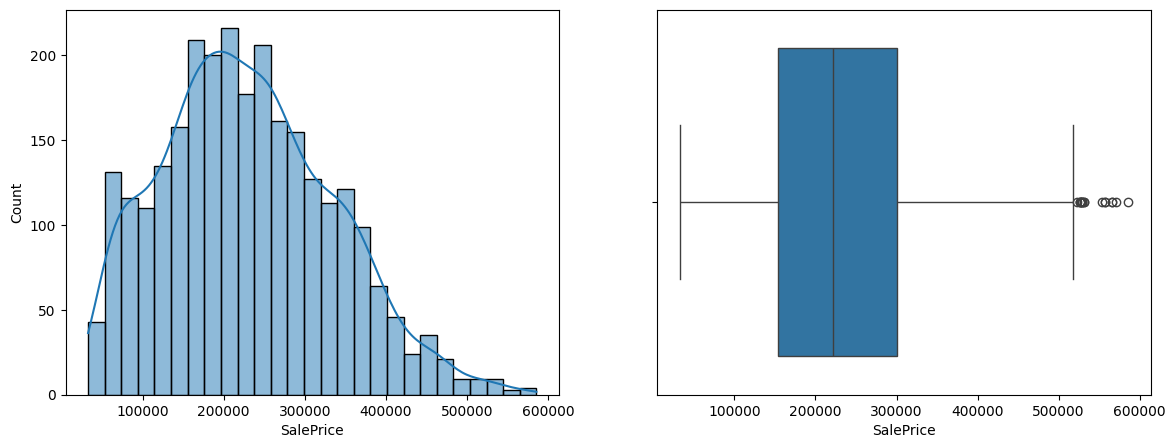

Skewness: 0.38608459274791307


count      2701.000000
mean     229511.365790
std      105079.891321
min       32743.000000
25%      153539.000000
50%      221238.000000
75%      300884.000000
max      585840.000000
Name: SalePrice, dtype: float64

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['SalePrice'], kde=True, ax=ax[0])
sns.boxplot(x=df['SalePrice'], ax=ax[1])
plt.show()

print('Skewness:', df['SalePrice'].skew())
df['SalePrice'].describe()

Setelah duplikat dibuang (2.701 baris), harga jual apartemen berkisar antara 32.743 sampai 585.840 Won, dengan rata-rata (229.511) sedikit lebih tinggi daripada median (221.238). Nilai skewness sebesar 0,39 menunjukkan distribusi hampir simetris dengan kemiringan tipis ke kanan, dan boxplot memperlihatkan beberapa unit bernilai tinggi di sisi kanan. Karena distribusi target tidak terlalu miring, transformasi log pada target tidak diperlukan dan harga dimodelkan dalam skala aslinya.

### **Plot 2: Harga berdasarkan fitur kategorikal**

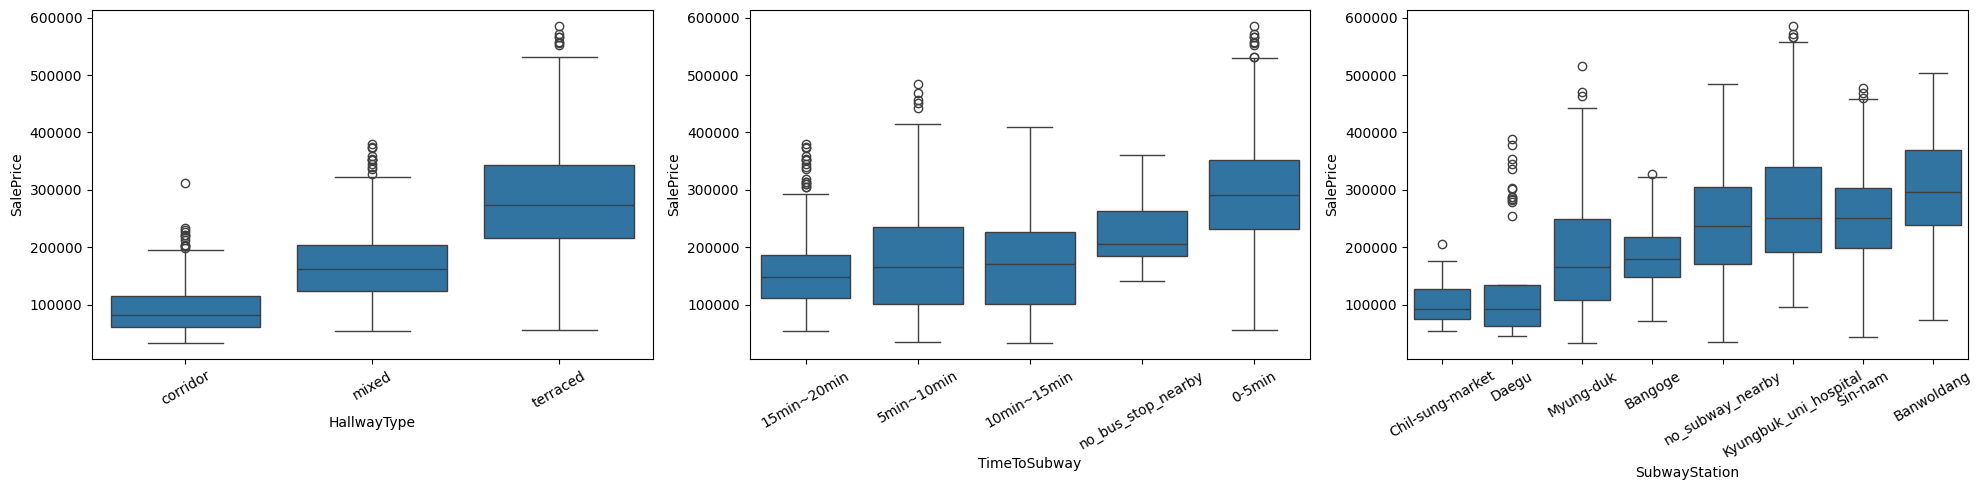

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, col in zip(ax, ['HallwayType', 'TimeToSubway', 'SubwayStation']):
    order = df.groupby(col)['SalePrice'].median().sort_values().index
    sns.boxplot(x=col, y='SalePrice', data=df, order=order, ax=a)
    a.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Interpretasi:**

- **HallwayType.** Median harga berbeda sangat jauh antar tipe: terraced sekitar 273.451, mixed sekitar 161.946, dan corridor sekitar 81.415. Jarak antar boxplot-nya juga hampir tidak tumpang tindih, sehingga tipe lorong kemungkinan menjadi pembeda harga yang paling kuat di antara fitur kategorikal. Perlu dicatat bahwa jumlah unit tiap tipe tidak seimbang (terraced 1.667, mixed 698, corridor 336).

- **TimeToSubway.** Unit yang berjarak 0-5 menit dari subway memiliki median harga tertinggi (sekitar 290.265), jauh di atas kelompok lainnya yang berada di kisaran 148.000-171.000. Di luar kelompok 0-5 menit, selisih antar kelompok kecil dan tidak sepenuhnya berurutan (misalnya 10-15 menit sedikit lebih tinggi daripada 5-10 menit). Kategori no_bus_stop_nearby (median sekitar 205.345) tidak mengikuti urutan jarak, karena kategori ini hanya muncul ketika tidak ada stasiun subway di dekat unit, sehingga bukan merupakan ukuran waktu tempuh.

- **SubwayStation.** Median harga bervariasi menurut stasiun terdekat, dari yang tertinggi Banwoldang (sekitar 295.575) hingga yang terendah Chil-sung-market (sekitar 92.920) dan Daegu (sekitar 93.141). Stasiun dengan harga terendah hanya memiliki sedikit unit (65 dan 54 unit), sehingga perlu hati-hati dalam menafsirkannya.

**Dampak untuk pemodelan:** ketiga fitur kategorikal tampak berhubungan dengan harga, sehingga seluruhnya dipertahankan dan di-encode. Hubungan ini bersifat pola dari data, bukan bukti sebab-akibat; misalnya, kemungkinan sebagian pengaruh stasiun sebenarnya mencerminkan tipe lorong atau karakteristik kompleks apartemen di sekitar stasiun tersebut.

In [8]:
for col in ['HallwayType', 'TimeToSubway', 'SubwayStation']:
    print(df.groupby(col)['SalePrice'].agg(['median', 'count']).round(0).sort_values('median'))
    print()

               median  count
HallwayType                 
corridor      81415.0    336
mixed        161946.0    698
terraced     273451.0   1667

                      median  count
TimeToSubway                       
15min~20min         148672.0    418
5min~10min          165486.0    501
10min~15min         170796.0    434
no_bus_stop_nearby  205345.0    100
0-5min              290265.0   1248

                         median  count
SubwayStation                         
Chil-sung-market        92920.0     65
Daegu                   93141.0     54
Myung-duk              165486.0    709
Bangoge                179867.0    280
no_subway_nearby       236726.0    188
Kyungbuk_uni_hospital  250884.0    692
Sin-nam                251327.0    380
Banwoldang             295575.0    333



### **Plot 3: Hubungan ukuran apartemen dan harga**

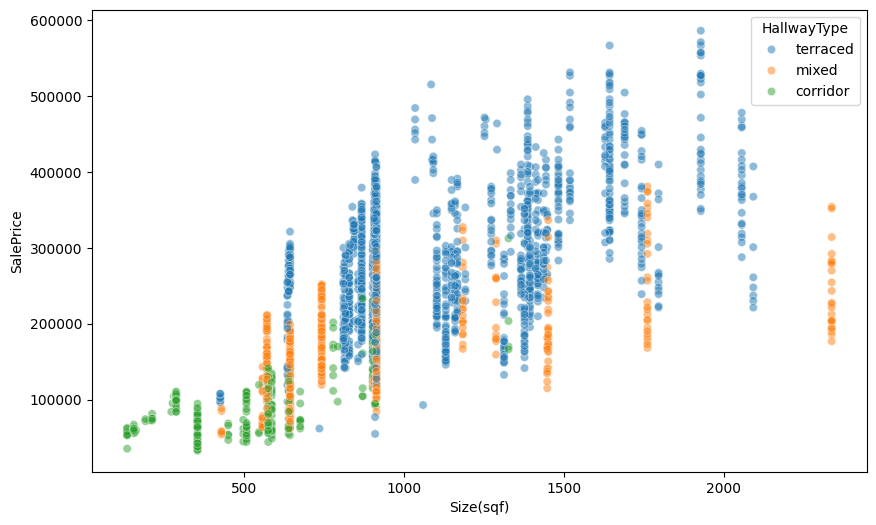

In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Size(sqf)', y='SalePrice', hue='HallwayType', data=df, alpha=0.5)
plt.show()

**Interpretasi:**

Ukuran apartemen memiliki hubungan positif yang jelas dengan harga jual (korelasi 0,66): semakin besar unit, harga cenderung semakin tinggi. Hubungan ini juga terlihat di dalam masing-masing tipe lorong (korelasi 0,52 sampai 0,68), sehingga ukuran berpengaruh terlepas dari tipenya.

Scatter plot juga menunjukkan titik-titik yang membentuk pita vertikal, karena ukuran unit hanya terdiri dari 89 nilai berbeda dan beberapa ukuran muncul sangat sering (misalnya 914 sqft, sebanyak 444 unit). Ini menandakan banyak unit memiliki denah ukuran yang sama.

Tipe terraced umumnya berada di bagian atas plot. Unit terraced memang cenderung lebih besar (median 914 sqft, dibandingkan 576 pada corridor), tetapi pada rentang ukuran yang sebanding (800-1.000 sqft) unit terraced tetap lebih mahal (median sekitar 247 ribu, dibandingkan sekitar 157 ribu pada corridor). Artinya, perbedaan harga antar tipe tidak hanya disebabkan oleh perbedaan ukuran.

**Dampak untuk pemodelan:** ukuran dan tipe lorong sama-sama menjadi fitur penting yang dipertahankan.

In [10]:
df.groupby('HallwayType')['Size(sqf)'].median()

HallwayType
corridor    576.0
mixed       743.0
terraced    914.0
Name: Size(sqf), dtype: float64

In [11]:
# 1. Korelasi ukuran dan harga untuk setiap tipe lorong
print('Korelasi ukuran-harga per tipe:')
for tipe in sorted(df['HallwayType'].unique()):
    data_tipe = df[df['HallwayType'] == tipe]                       
    korelasi = data_tipe['Size(sqf)'].corr(data_tipe['SalePrice'])  
    print(tipe, ':', round(korelasi, 2))

# 2. Jumlah unit berukuran 914 sqft
unit_914 = df[df['Size(sqf)'] == 914]
print('\nJumlah unit berukuran 914 sqft:', len(unit_914))

# 3. Median harga untuk unit berukuran 800-1.000 sqft, per tipe lorong
ukuran_800_1000 = df[(df['Size(sqf)'] >= 800) & (df['Size(sqf)'] <= 1000)]
median_harga = ukuran_800_1000.groupby('HallwayType')['SalePrice'].median()
print('\nMedian harga pada ukuran 800-1.000 sqft:')
print(median_harga)

Korelasi ukuran-harga per tipe:
corridor : 0.68
mixed : 0.54
terraced : 0.52

Jumlah unit berukuran 914 sqft: 444

Median harga pada ukuran 800-1.000 sqft:
HallwayType
corridor    156637.0
mixed       171017.0
terraced    246566.0
Name: SalePrice, dtype: float64


### **Plot 4: Korelasi antar fitur numerik**

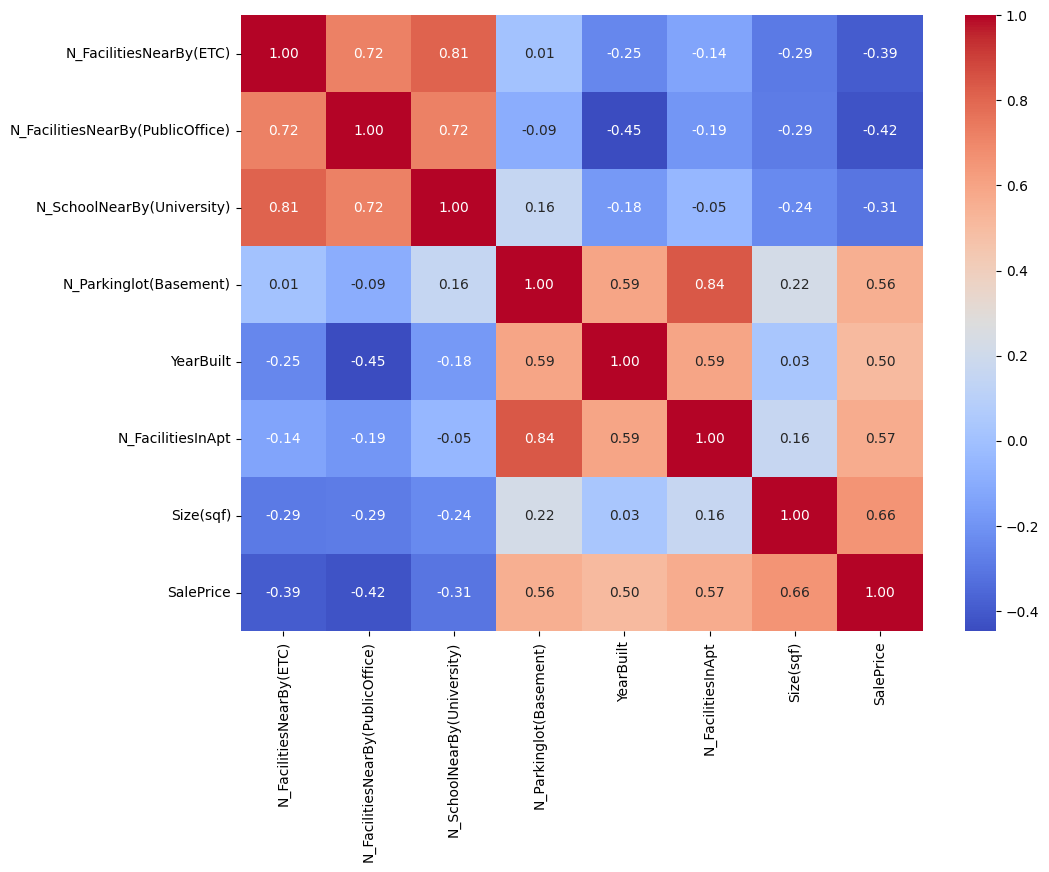

In [12]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [13]:
df.groupby('HallwayType')[['N_FacilitiesNearBy(ETC)', 'N_FacilitiesNearBy(PublicOffice)',
                           'N_SchoolNearBy(University)']].mean().round(2)

,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University)
HallwayType,,,
corridor,2.61,5.32,2.96
mixed,4.19,5.58,4.30
terraced,0.78,3.12,1.95


In [14]:
pd.crosstab(df['HallwayType'], df['SubwayStation'])

SubwayStation,Bangoge,Banwoldang,Chil-sung-market,Daegu,Kyungbuk_uni_hospital,Myung-duk,Sin-nam,no_subway_nearby
HallwayType,,,,,,,,
corridor,0,32,0,41,44,144,47,28
mixed,280,0,65,0,0,353,0,0
terraced,0,301,0,13,648,212,333,160


**Interpretasi:**

- **Fitur yang berkorelasi positif dengan harga.** Ukuran apartemen (Size(sqf)) memiliki korelasi paling kuat dengan SalePrice (0,66), diikuti jumlah fasilitas di dalam apartemen (0,57), jumlah parkir basement (0,56), dan tahun dibangun (0,50). Unit yang lebih besar, lebih baru, dan memiliki fasilitas lebih banyak cenderung dihargai lebih tinggi.

- **Fitur yang berkorelasi negatif dengan harga.** Jumlah fasilitas di sekitar (ETC dan PublicOffice) dan jumlah universitas di sekitar berkorelasi negatif dengan harga (-0,31 sampai -0,42). Hal ini kurang intuitif. Dari data, unit bertipe terraced yang paling mahal justru memiliki fasilitas sekitar paling sedikit (rata-rata ETC 0,78, dibandingkan 4,19 pada mixed), sehingga korelasi negatif ini kemungkinan mencerminkan perbedaan tipe lorong dan lokasi, bukan pengaruh langsung fasilitas sekitar terhadap harga.

- **Korelasi antar fitur.** Beberapa fitur saling berkorelasi tinggi, misalnya parkir basement dan fasilitas di dalam apartemen (0,84) serta fasilitas sekitar (ETC) dan universitas sekitar (0,81). Artinya sebagian fitur membawa informasi yang mirip.

**Dampak untuk pemodelan:** korelasi antar fitur yang tinggi dapat menyulitkan penafsiran koefisien pada model linear, sedangkan model berbasis pohon relatif tidak terpengaruh. Seluruh fitur tetap dipertahankan, dan interpretasi pentingnya fitur nanti dibaca dengan hati-hati. Perlu diingat bahwa korelasi hanya menunjukkan hubungan linear dan tidak membuktikan sebab-akibat.

### **Plot 5: Tahun dibangun dan harga**

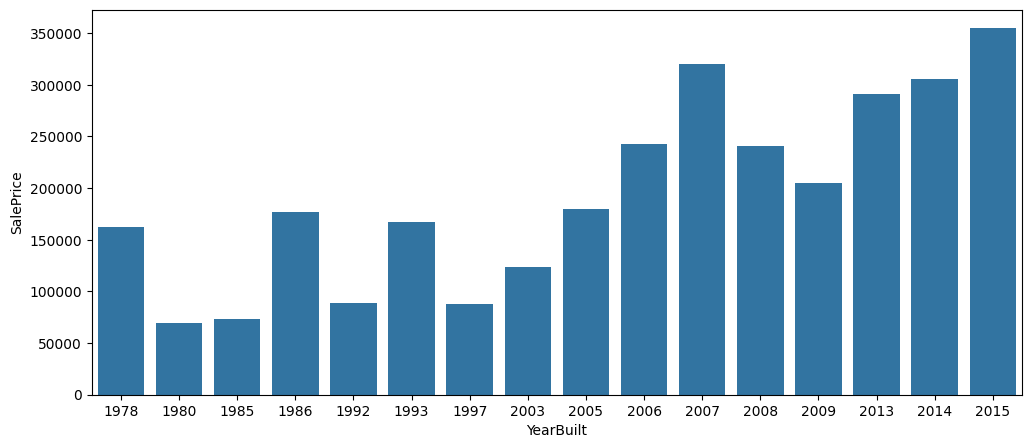

In [15]:
plt.figure(figsize=(12, 5))
sns.barplot(x='YearBuilt', y='SalePrice', data=df, estimator='median', errorbar=None)
plt.show()

**Interpretasi:**

Secara umum, apartemen yang dibangun lebih baru cenderung dihargai lebih tinggi (korelasi 0,50), dengan median harga tertinggi pada unit yang dibangun tahun 2015, diikuti 2007 dan 2014. Namun, polanya tidak naik secara konsisten: median harga tahun 2013 (sekitar 291 ribu) lebih rendah daripada 2007 (sekitar 320 ribu) dan 2014 (sekitar 305 ribu), serta tahun 2009 (sekitar 205 ribu) lebih rendah daripada 2006 (sekitar 242 ribu) dan 2008 (sekitar 241 ribu).

Dataset hanya mencakup 16 tahun pembangunan, dan sebagian besar tahun didominasi oleh satu tipe lorong (13 dari 16 tahun memiliki satu tipe yang mencakup minimal 80% unit). Unit yang dibangun sampai 1997 kebanyakan bertipe mixed dan corridor, sedangkan unit yang dibangun sejak 2006 hampir seluruhnya bertipe terraced (sekitar 96%). Di dalam tiap tipe, hubungan tahun dibangun dengan harga lebih lemah dan arahnya berbeda (corridor -0,38, mixed 0,16, terraced 0,32), sehingga pengaruh tahun dibangun yang terlihat secara keseluruhan sebagian besar kemungkinan mencerminkan perbedaan tipe lorong, bukan umur bangunan itu sendiri.

Beberapa tahun hanya memiliki sedikit unit (misalnya 1980 dengan 4 unit dan 2003 dengan 7 unit), sehingga median harganya kurang dapat diandalkan.

**Dampak untuk pemodelan:** YearBuilt tetap dipertahankan sebagai fitur, tetapi pengaruhnya perlu ditafsirkan dengan hati-hati karena berkaitan erat dengan HallwayType.

In [16]:
df.groupby('YearBuilt')['SalePrice'].agg(['median', 'count'])

,median,count
YearBuilt,,
1978,162388.5,44
1980,69468.5,4
1985,73451.0,41
1986,176991.0,214
1992,88495.0,221
1993,167256.0,276
1997,88052.5,58
2003,123893.0,7
2005,179867.0,280


In [17]:
for h, g in df.groupby('HallwayType'):
    print(h, round(g['YearBuilt'].corr(g['SalePrice']), 2))

corridor -0.38
mixed 0.16
terraced 0.32


In [18]:
ct = pd.crosstab(df['YearBuilt'], df['HallwayType'], normalize='index').round(2)
print(ct)
print('Tahun dengan satu tipe >= 80% unit:', (ct.max(axis=1) >= 0.8).sum(), 'dari', len(ct))
print('\nKomposisi tipe, dibangun sejak 2006:')
print(df[df['YearBuilt'] >= 2006]['HallwayType'].value_counts(normalize=True).round(2))
print('\nKomposisi tipe, dibangun sampai 1997:')
print(df[df['YearBuilt'] <= 1997]['HallwayType'].value_counts(normalize=True).round(2))

HallwayType  corridor  mixed  terraced
YearBuilt                             
1978             1.00   0.00      0.00
1980             0.00   0.00      1.00
1985             1.00   0.00      0.00
1986             0.22   0.00      0.78
1992             0.65   0.35      0.00
1993             0.00   1.00      0.00
1997             0.00   1.00      0.00
2003             0.00   1.00      0.00
2005             0.00   1.00      0.00
2006             0.00   0.00      1.00
2007             0.00   0.00      1.00
2008             0.00   0.00      1.00
2009             0.00   0.00      1.00
2013             0.00   0.00      1.00
2014             0.28   0.00      0.72
2015             0.00   0.00      1.00
Tahun dengan satu tipe >= 80% unit: 13 dari 16

Komposisi tipe, dibangun sejak 2006:
HallwayType
terraced    0.96
corridor    0.04
Name: proportion, dtype: float64

Komposisi tipe, dibangun sampai 1997:
HallwayType
mixed       0.48
corridor    0.32
terraced    0.20
Name: proportion, dtype: float64

## **Data Preprocessing**

### **3.1 Duplikasi dataframe dan info tiap fitur**

In [19]:
df_model = df.copy()

In [20]:
listItem = []
for col in df_model.columns:
    listItem.append([col, df_model[col].dtype, df_model[col].isna().sum(),
                     round((df_model[col].isna().sum()/len(df_model[col]))*100, 2),
                     df_model[col].nunique(),
                     list(df_model[col].drop_duplicates().sample(2).values)])

df_model_desc = pd.DataFrame(columns=['dataFeatures', 'dataType', 'null', 'nullPct', 'unique', 'uniqueSample'],
                             data=listItem)
df_model_desc

,dataFeatures,dataType,null,nullPct,unique,uniqueSample
0,HallwayType,object,0,0.0,3,"[mixed, terraced]"
1,TimeToSubway,object,0,0.0,5,"[no_bus_stop_nearby, 0-5min]"
2,SubwayStation,object,0,0.0,8,"[no_subway_nearby, Myung-duk]"
3,N_FacilitiesNearBy(ETC),float64,0,0.0,4,"[5.0, 1.0]"
4,N_FacilitiesNearBy(PublicOffice),float64,0,0.0,8,"[5.0, 1.0]"
5,N_SchoolNearBy(University),float64,0,0.0,6,"[2.0, 1.0]"
6,N_Parkinglot(Basement),float64,0,0.0,20,"[218.0, 108.0]"
7,YearBuilt,int64,0,0.0,16,"[1997, 1993]"
8,N_FacilitiesInApt,int64,0,0.0,9,"[7, 9]"
9,Size(sqf),int64,0,0.0,89,"[277, 1288]"


### **3.2 Missing Value**

<Axes: >

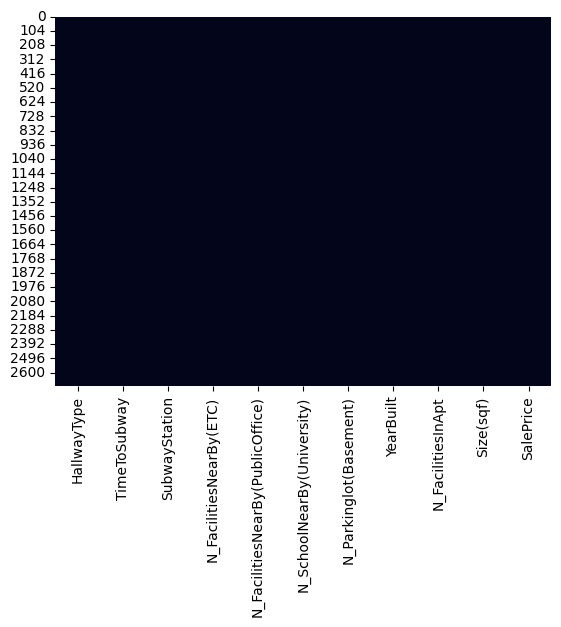

In [21]:
sns.heatmap(df_model.isnull(), cbar=False)

### **3.3 Data Duplikat**

In [22]:
df_model.duplicated().sum()

np.int64(0)

Duplikat sudah dibuang pada tahap Data Understanding, sehingga df_model tidak lagi memuat baris duplikat.

### **3.4 Drop Kolom**

**Keputusan: tidak ada kolom yang dibuang.**

Seluruh 10 fitur relevan terhadap harga jual, dan dataset tidak memiliki kolom identitas (seperti id atau nama) yang tidak berkontribusi pada prediksi. Tidak ada pula kolom yang baru diketahui setelah unit terjual.

### **3.5 Nilai yang tidak masuk akal**

In [23]:
# Statistik deskriptif fitur numerikal
num_features = [f for f in df_model.columns if df_model[f].dtypes != 'object']
df_model[num_features].describe()

,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University),N_Parkinglot(Basement),YearBuilt,N_FacilitiesInApt,Size(sqf),SalePrice
count,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000
mean,1.890411,4.027027,2.680489,533.746390,2002.358386,5.713439,984.028878,229511.365790
std,2.153168,1.887486,1.504470,418.224859,9.151949,2.386552,391.982619,105079.891321
min,0.000000,0.000000,0.000000,0.000000,1978.000000,1.000000,135.000000,32743.000000
25%,0.000000,3.000000,2.000000,181.000000,1993.000000,4.000000,743.000000,153539.000000
50%,1.000000,4.000000,2.000000,536.000000,2006.000000,5.000000,910.000000,221238.000000
75%,5.000000,5.000000,4.000000,798.000000,2007.000000,7.000000,1167.000000,300884.000000
max,5.000000,7.000000,5.000000,1321.000000,2015.000000,10.000000,2337.000000,585840.000000


In [24]:
# Hubungan SubwayStation dan TimeToSubway
pd.crosstab(df_model['SubwayStation'], df_model['TimeToSubway'])

TimeToSubway,0-5min,10min~15min,15min~20min,5min~10min,no_bus_stop_nearby
SubwayStation,,,,,
Bangoge,0,0,0,280,0
Banwoldang,301,0,0,32,0
Chil-sung-market,0,0,65,0,0
Daegu,0,0,0,54,0
Kyungbuk_uni_hospital,402,290,0,0,0
Myung-duk,212,144,353,0,0
Sin-nam,333,0,0,47,0
no_subway_nearby,0,0,0,88,100


In [25]:
# Jumlah data dengan parkir basement = 0
(df_model['N_Parkinglot(Basement)'] == 0).sum()

np.int64(355)

**Keputusan: ketiga temuan berikut dipertahankan.**

1. **Kategori `no_bus_stop_nearby` pada `TimeToSubway`.** Kategori ini hanya muncul pada unit yang tidak memiliki stasiun subway di dekatnya (`no_subway_nearby`), sehingga bukan merupakan ukuran waktu tempuh. Karena itu kategori ini tidak dapat diperlakukan sebagai urutan jarak, dan `TimeToSubway` di-encode dengan One-Hot Encoding.

2. **Unit `no_subway_nearby` dengan `TimeToSubway` = `5min-10min` (88 baris).** Dari 188 unit tanpa stasiun subway di dekatnya, 100 unit bernilai `no_bus_stop_nearby` dan 88 unit tercatat 5-10 menit ke subway. Kombinasi kedua ini tidak konsisten secara logika, karena unit tanpa subway di dekatnya seharusnya tidak punya waktu tempuh ke subway. Harganya juga berbeda jauh (median sekitar 299.999 dibandingkan sekitar 205.345 pada kelompok `no_bus_stop_nearby`), sehingga kedua kelompok ini tidak dapat digabung begitu saja. Karena tidak ada dasar untuk mengoreksi nilainya, data dipertahankan dan dicatat sebagai keterbatasan data. Kemungkinan penyebabnya adalah pencatatan stasiun dan waktu tempuh yang berasal dari sumber yang berbeda, tetapi hal ini tidak dapat dipastikan dari dataset.

3. **`N_Parkinglot(Basement)` bernilai 0 (355 baris).** Tidak dapat dipastikan apakah unit tersebut memang tidak memiliki parkir basement atau datanya tidak tercatat. Karena tidak ada dasar untuk mengubahnya, nilai dipertahankan dan dicatat sebagai keterbatasan data.

### **3.6 Outlier**

In [26]:
def find_anomalies(data):
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    limit = iqr*1.5
    print(f'IQR: {iqr}')
    limit_bawah = q1 - limit
    limit_atas = q3 + limit
    print(f'limit_bawah: {limit_bawah}')
    print(f'limit_atas: {limit_atas}')
    print(f'jumlah outlier: {((data < limit_bawah) | (data > limit_atas)).sum()}')

In [27]:
find_anomalies(df_model['SalePrice'])
find_anomalies(df_model['Size(sqf)'])

IQR: 147345.0
limit_bawah: -67478.5
limit_atas: 521901.5
jumlah outlier: 17
IQR: 424.0
limit_bawah: 107.0
limit_atas: 1803.0
jumlah outlier: 84


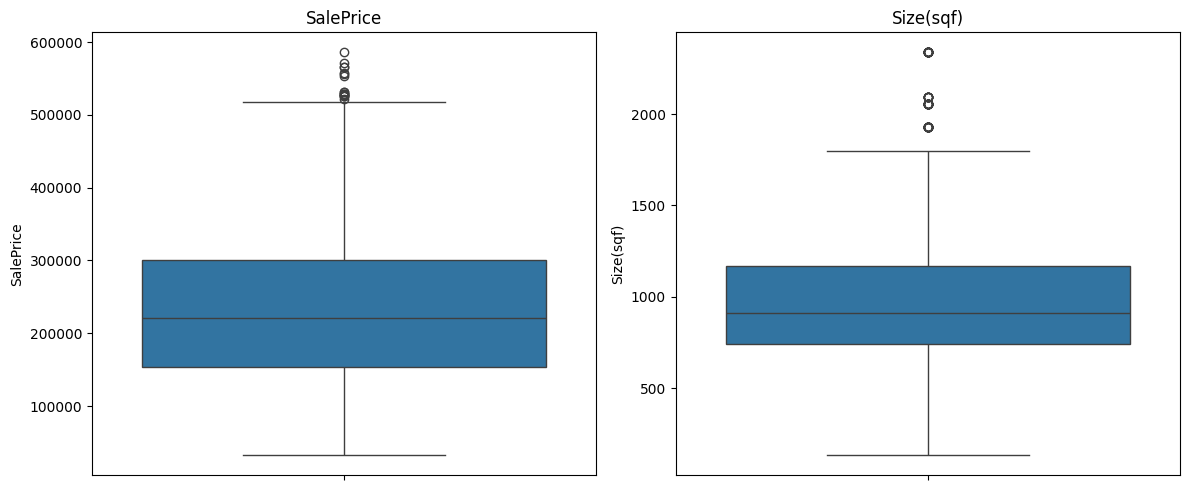

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=df_model['SalePrice'], ax=ax[0])
ax[0].set_title('SalePrice')
sns.boxplot(y=df_model['Size(sqf)'], ax=ax[1])
ax[1].set_title('Size(sqf)')
plt.tight_layout()
plt.show()

**Keputusan: outlier dipertahankan.**

Dengan metode IQR, terdapat 17 outlier pada `SalePrice` (batas atas 521.901,5; sekitar 0,6% dari 2.701 baris) dan 84 outlier pada `Size(sqf)` (batas atas 1.803; sekitar 3,1%). Seluruhnya berada di sisi atas, yaitu unit yang mahal dan berukuran besar.

Outlier dipertahankan karena merupakan data yang valid (apartemen besar dan mahal memang ada di pasar), jumlahnya relatif kecil, dan ukuran adalah prediktor yang kuat terhadap harga sehingga membuang unit besar akan menghilangkan informasi penting. Model berbasis pohon yang dipakai juga relatif tahan terhadap outlier.

**Limitasi:** model mungkin kurang akurat untuk unit dengan ukuran atau harga yang sangat ekstrem karena datanya sedikit.

### **3.7 Clean dataset**

In [29]:
df_model.head()

,HallwayType,TimeToSubway,SubwayStation,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University),N_Parkinglot(Basement),YearBuilt,N_FacilitiesInApt,Size(sqf),SalePrice
0,terraced,0-5min,Kyungbuk_uni_hospital,0.0,3.0,2.0,1270.0,2007,10,1387,346017
1,terraced,10min~15min,Kyungbuk_uni_hospital,1.0,5.0,1.0,0.0,1986,4,914,150442
2,mixed,15min~20min,Chil-sung-market,1.0,7.0,3.0,56.0,1997,5,558,61946
3,mixed,5min~10min,Bangoge,5.0,5.0,4.0,798.0,2005,7,914,165486
4,terraced,0-5min,Sin-nam,0.0,1.0,2.0,536.0,2006,5,1743,311504


In [30]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2701 entries, 0 to 2700
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HallwayType                       2701 non-null   object 
 1   TimeToSubway                      2701 non-null   object 
 2   SubwayStation                     2701 non-null   object 
 3   N_FacilitiesNearBy(ETC)           2701 non-null   float64
 4   N_FacilitiesNearBy(PublicOffice)  2701 non-null   float64
 5   N_SchoolNearBy(University)        2701 non-null   float64
 6   N_Parkinglot(Basement)            2701 non-null   float64
 7   YearBuilt                         2701 non-null   int64  
 8   N_FacilitiesInApt                 2701 non-null   int64  
 9   Size(sqf)                         2701 non-null   int64  
 10  SalePrice                         2701 non-null   int64  
dtypes: float64(4), int64(4), object(3)
memory usage: 232.2+ KB


Setelah proses preprocessing, dataset yang digunakan untuk pemodelan terdiri dari **2.701 baris dan 11 kolom** (10 fitur dan 1 target `SalePrice`), tanpa missing value.

## **Modelling**

### **4.1 Import library & Encoding**

In [31]:
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [32]:
cat_cols = ['HallwayType', 'TimeToSubway', 'SubwayStation']
num_cols = [c for c in df_model.columns if c not in cat_cols + ['SalePrice']]

# Untuk model pohon (tidak sensitif skala)
prep_tree = ColumnTransformer(
    [('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough')

# Untuk Linear Regression dan KNN (sensitif skala)
prep_scaled = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols)])

### **4.2 Data Splitting**

In [33]:
X = df_model.drop(columns='SalePrice')
y = df_model['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (2160, 10) | Test: (541, 10)


In [34]:
prep_tree.fit_transform(X_train).shape

(2160, 23)

### **4.3 Benchmark lima model dengan cross-validation**

In [35]:
models = {
    'Linear Regression': Pipeline([('prep', prep_scaled), ('model', LinearRegression())]),
    'KNN':               Pipeline([('prep', prep_scaled), ('model', KNeighborsRegressor())]),
    'Decision Tree':     Pipeline([('prep', prep_tree),   ('model', DecisionTreeRegressor(random_state=42))]),
    'Random Forest':     Pipeline([('prep', prep_tree),   ('model', RandomForestRegressor(random_state=42))]),
    'XGBoost':           Pipeline([('prep', prep_tree),   ('model', XGBRegressor(random_state=42))]),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'rmse': 'neg_root_mean_squared_error',
           'mae':  'neg_mean_absolute_error',
           'mape': 'neg_mean_absolute_percentage_error'}

rows = []
for name, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'Model': name,
                 'Mean_RMSE': -r['test_rmse'].mean(),
                 'Std_RMSE':  r['test_rmse'].std(),
                 'Mean_MAE':  -r['test_mae'].mean(),
                 'Mean_MAPE': -r['test_mape'].mean()})

cv_result = pd.DataFrame(rows).sort_values('Mean_RMSE').reset_index(drop=True)
cv_result

,Model,Mean_RMSE,Std_RMSE,Mean_MAE,Mean_MAPE
0,Random Forest,46262.128091,1343.911255,37318.852603,0.192704
1,XGBoost,46333.150000,1327.111652,37382.722656,0.192921
2,Decision Tree,46460.515446,1566.384877,37405.614662,0.193454
3,KNN,48824.497215,924.488163,38880.222222,0.199618
4,Linear Regression,52127.112623,1270.149640,42006.340156,0.218370


**Interpretasi benchmark:**

Berdasarkan cross-validation, Random Forest, XGBoost, dan Decision Tree memberikan performa terbaik dan hampir sama (RMSE sekitar 46.260 sampai 46.460, MAPE sekitar 19,3%). Selisih antar ketiganya (sekitar 70 sampai 200) jauh lebih kecil daripada standar deviasi RMSE masing-masing (sekitar 1.300 sampai 1.570), sehingga perbedaannya tidak dapat dianggap bermakna secara statistik. KNN berada di tengah (RMSE sekitar 48.800), dan Linear Regression paling lemah (RMSE sekitar 52.130, MAPE 21,8%).

Linear Regression kemungkinan kurang baik karena hubungan fitur dengan harga tidak sepenuhnya linear; misalnya harga sangat bergantung pada kategori seperti tipe lorong, dan pengaruh fitur dapat saling berinteraksi, sedangkan model berbasis pohon lebih mampu menangkap pola seperti ini.

Nilai RMSE selalu lebih besar daripada MAE karena RMSE mengkuadratkan selisih sehingga memberi bobot lebih besar pada kesalahan prediksi yang besar.

### **4.4 Evaluasi dua kandidat di test set**

In [36]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

def evaluate(model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    return {'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
            'MAE':  mean_absolute_error(y_test, pred),
            'MAPE': mean_absolute_percentage_error(y_test, pred),
            'R2':   r2_score(y_test, pred)}

before = pd.DataFrame({n: evaluate(models[n]) for n in ['Random Forest', 'XGBoost']}).T
before

,RMSE,MAE,MAPE,R2
Random Forest,48193.388347,39009.222223,0.200355,0.781355
XGBoost,48005.410362,38962.675781,0.198781,0.783057


In [37]:
from sklearn.dummy import DummyRegressor

baseline = Pipeline([('prep', prep_tree), ('model', DummyRegressor(strategy='mean'))])
baseline_result = pd.DataFrame({'Baseline (rata-rata)': evaluate(baseline)}).T

pd.concat([baseline_result, before])

,RMSE,MAE,MAPE,R2
Baseline (rata-rata),103097.788215,84204.859406,0.544284,-0.000606
Random Forest,48193.388347,39009.222223,0.200355,0.781355
XGBoost,48005.410362,38962.675781,0.198781,0.783057


**Interpretasi baseline:**

Sebagai pembanding, baseline yang selalu memprediksi harga rata-rata data train menghasilkan RMSE sekitar 103.098, MAE sekitar 84.205, MAPE sekitar 54,4%, dan R² mendekati 0. Dibandingkan baseline ini, XGBoost setelah tuning (RMSE 47.642; MAE 38.773; MAPE 19,8%) menurunkan RMSE dan MAE sekitar 54%, sehingga model memberikan nilai tambah yang jelas dibanding menebak harga rata-rata.

**Interpretasi evaluasi pada test set:**

Pada data test, XGBoost (RMSE 48.005; MAE 38.963; MAPE 19,9%; R² 0,783) dan Random Forest (RMSE 48.193; MAE 39.009; MAPE 20,0%; R² 0,781) kembali menunjukkan hasil yang hampir identik. RMSE pada test set sedikit lebih tinggi daripada hasil cross-validation (sekitar 46.300), tetapi selisihnya kecil, sehingga tidak ada indikasi overfitting yang berarti.

Karena performa tiga model teratas hampir sama, XGBoost dipilih sebagai model akhir untuk dioptimasi lebih lanjut dengan hyperparameter tuning, berdasarkan pertimbangan berikut dan bukan berdasarkan selisih skor.

Pertama, model berbasis pohon lebih cocok daripada model linear untuk data ini: Linear Regression paling lemah di cross-validation (RMSE sekitar 52.130; MAPE 21,8%), sedangkan Random Forest, XGBoost, dan Decision Tree berada di RMSE sekitar 46.260 sampai 46.460 (MAPE sekitar 19,3%). Hal ini masuk akal karena harga sangat bergantung pada kategori seperti HallwayType (median terraced sekitar 273 ribu dibandingkan corridor sekitar 81 ribu) dan fitur-fiturnya saling berinteraksi. Model pohon juga tidak sensitif terhadap skala fitur, relatif lebih tahan terhadap outlier, dan tidak terlalu terganggu oleh korelasi antar fitur yang tinggi.

Kedua, di antara model pohon, XGBoost adalah model ensemble yang membangun pohon secara bertahap, sehingga setiap pohon baru memperbaiki kesalahan pohon sebelumnya. Secara umum, model ensemble lebih tahan overfitting daripada satu Decision Tree, meskipun pada benchmark ini skornya hampir sama dan standar deviasi RMSE antar fold ketiga model berdekatan (XGBoost 1.327, Random Forest 1.344, Decision Tree 1.566), sehingga angka tersebut tidak dapat dijadikan bukti kestabilan. XGBoost juga memiliki banyak hyperparameter dan regularisasi bawaan yang dapat disetel. Pada test set XGBoost sedikit lebih baik daripada Random Forest (RMSE 48.005 dibandingkan 48.193), tetapi selisih ini kecil dan tidak dianggap bermakna.

Catatan: hanya XGBoost yang dituning, sehingga tidak diketahui apakah Random Forest yang dituning dapat menyamai performanya.

### **4.5 Hyperparameter tuning (XGBoost)**

Tuning mencari kombinasi parameter yang membuat model lebih akurat. Kita pakai RandomizedSearchCV, yang mencoba kombinasi acak (lebih cepat daripada mencoba semuanya), dengan cross-validation yang sama seperti benchmark.

In [38]:
space = {
    'model__max_depth':        list(range(2, 9)),
    'model__learning_rate':    list(np.arange(1, 31) / 100),
    'model__n_estimators':     list(range(100, 501, 50)),
    'model__subsample':        list(np.arange(5, 11) / 10),
    'model__colsample_bytree': list(np.arange(5, 11) / 10),
    'model__min_child_weight': [1, 3, 5, 7],
    'model__reg_alpha':        list(np.logspace(-3, 1, 8)),
}

random_xgb = RandomizedSearchCV(
    models['XGBoost'], param_distributions=space, n_iter=40,
    cv=cv, scoring=scoring, refit='rmse', n_jobs=-1, random_state=42)
random_xgb.fit(X_train, y_train)

print('Best CV RMSE:', -random_xgb.best_score_)
print('Best params :', random_xgb.best_params_)

Best CV RMSE: 45943.7578125
Best params : {'model__subsample': np.float64(0.8), 'model__reg_alpha': np.float64(0.003727593720314938), 'model__n_estimators': 450, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': np.float64(0.02), 'model__colsample_bytree': np.float64(0.9)}


### **4.6 Perbandingan sebelum dan sesudah tuning**

In [39]:
best_model = random_xgb.best_estimator_
after = pd.DataFrame({'XGBoost (tuned)': evaluate(best_model)}).T

comparison = pd.concat([before.loc[['XGBoost']].rename(index={'XGBoost': 'XGBoost (default)'}), after])
comparison

,RMSE,MAE,MAPE,R2
XGBoost (default),48005.410362,38962.675781,0.198781,0.783057
XGBoost (tuned),47642.481883,38772.742188,0.198173,0.786325


**Interpretasi hasil tuning:**

Setelah hyperparameter tuning, performa XGBoost pada test set meningkat tipis: RMSE turun dari 48.005 menjadi 47.642 (sekitar 0,8%), MAE dari 38.963 menjadi 38.773, MAPE dari 19,88% menjadi 19,82%, dan R² naik dari 0,783 menjadi 0,786. Peningkatan ini sangat kecil, sehingga tuning belum memberi perbaikan yang berarti.

Parameter terbaik menunjukkan kecenderungan model yang relatif sederhana (kedalaman pohon 3) dengan pembelajaran bertahap (learning rate 0,02 dan 450 pohon). Peningkatan juga terlihat kecil pada cross-validation (RMSE terbaik 45.944 dibandingkan 46.333 pada model default), sehingga tuning pada ruang pencarian ini belum banyak membantu. Karena pencarian hanya mencoba 40 kombinasi acak dari ruang parameter yang besar, belum dapat disimpulkan bahwa batas performa model ditentukan oleh informasi pada fitur; hal ini perlu diuji dengan pencarian yang lebih luas dan penambahan fitur baru.

### **4.7 Actual vs predicted dan feature importance**

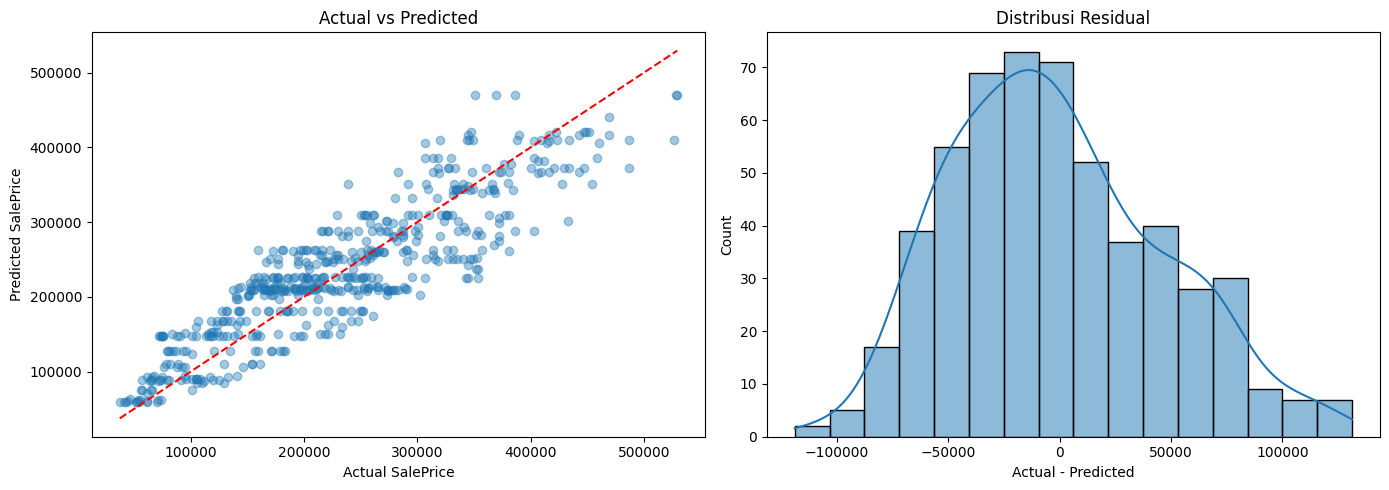

In [40]:
pred = best_model.predict(X_test)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, pred, alpha=0.4)
lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, 'r--')
ax[0].set(title='Actual vs Predicted', xlabel='Actual SalePrice', ylabel='Predicted SalePrice')

sns.histplot(y_test - pred, kde=True, ax=ax[1])
ax[1].set(title='Distribusi Residual', xlabel='Actual - Predicted')
plt.tight_layout()
plt.show()

In [41]:
res = X_test.copy()
res['actual'] = y_test
res['pred'] = pred
res['error'] = res['actual'] - res['pred']
res['abs_pct_error'] = res['error'].abs() / res['actual']

print(res.groupby('HallwayType').agg(n=('actual', 'size'),
                                     MAE=('error', lambda x: x.abs().mean()),
                                     MAPE=('abs_pct_error', 'mean')).round(3))

res['kuartil_harga'] = pd.qcut(res['actual'], 4, labels=['Q1 termurah', 'Q2', 'Q3', 'Q4 termahal'])
print(res.groupby('kuartil_harga').agg(MAE=('error', lambda x: x.abs().mean()),
                                       MAPE=('abs_pct_error', 'mean'),
                                       rata2_error=('error', 'mean')).round(3))

print('Prediksi dalam ±20%:', (res['abs_pct_error'] <= 0.2).mean())
print('Skewness residual:', res['error'].skew())

               n        MAE   MAPE
HallwayType                       
corridor      56  22099.335  0.243
mixed        141  42024.120  0.288
terraced     344  40154.328  0.154
                     MAE   MAPE  rata2_error
kuartil_harga                               
Q1 termurah    32644.006  0.321   -23381.851
Q2             36264.531  0.195   -22253.469
Q3             36175.029  0.139    11074.057
Q4 termahal    50155.692  0.136    28214.530
Prediksi dalam ±20%: 0.5619223659889094
Skewness residual: 0.4058812699727415


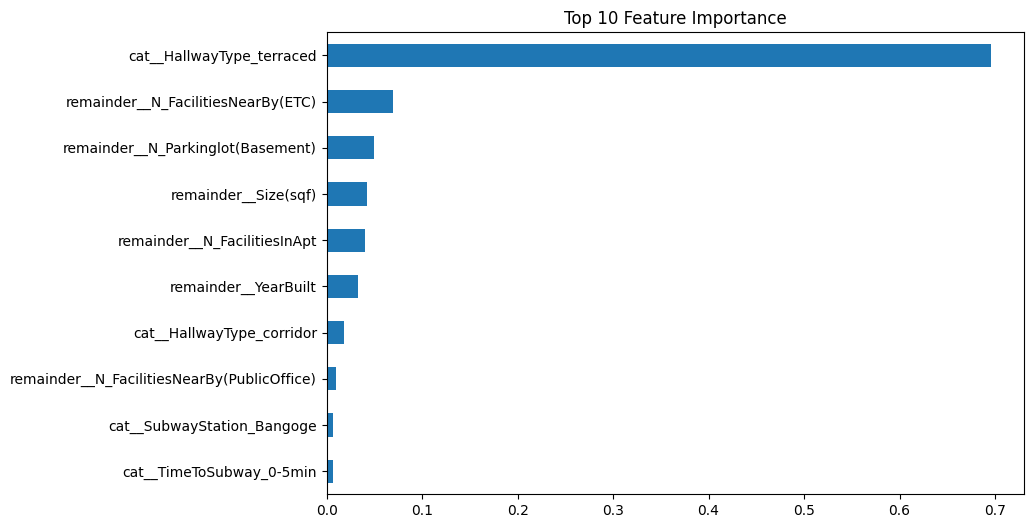

cat__HallwayType_terraced                      0.695699
remainder__N_FacilitiesNearBy(ETC)             0.069552
remainder__N_Parkinglot(Basement)              0.049820
remainder__Size(sqf)                           0.042349
remainder__N_FacilitiesInApt                   0.040350
remainder__YearBuilt                           0.032744
cat__HallwayType_corridor                      0.018131
remainder__N_FacilitiesNearBy(PublicOffice)    0.009480
cat__SubwayStation_Bangoge                     0.006947
cat__TimeToSubway_0-5min                       0.006402
dtype: float32

In [42]:
feat_names = best_model['prep'].get_feature_names_out()
importance = pd.Series(best_model['model'].feature_importances_, index=feat_names).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
importance.head(10).sort_values().plot(kind='barh', title='Top 10 Feature Importance')
plt.show()
importance.head(10)

In [43]:
# Seberapa sering harga aktual jatuh dalam rentang prediksi ± MAE
pred = best_model.predict(X_test)
abs_err = np.abs(y_test - pred)
mae = abs_err.mean()

print('MAE:', round(mae))
print('Persentase prediksi dengan error <= MAE:', round((abs_err <= mae).mean(), 3))

print('\nPersentil error absolut (Won):')
print(abs_err.quantile([0.5, 0.8, 0.9]).round(0))

print('\nPersentil error persentase:')
print((abs_err / y_test).quantile([0.5, 0.8, 0.9]).round(3))

MAE: 38773
Persentase prediksi dengan error <= MAE: 0.527

Persentil error absolut (Won):
0.5    34656.0
0.8    61999.0
0.9    74115.0
Name: SalePrice, dtype: float64

Persentil error persentase:
0.5    0.176
0.8    0.304
0.9    0.371
Name: SalePrice, dtype: float64


**Interpretasi feature importance dan hasil prediksi:**

Fitur yang paling berpengaruh adalah tipe lorong. HallwayType_terraced menyumbang sekitar 70% dari total importance, dan bersama HallwayType_corridor (1,8%) tipe lorong menjelaskan lebih dari 71%. Hal ini konsisten dengan hasil EDA, yang menunjukkan perbedaan harga antar tipe lorong sangat besar. Fitur berikutnya jauh lebih kecil: jumlah fasilitas sekitar (ETC), parkir basement, ukuran, fasilitas di dalam apartemen, dan tahun dibangun (masing-masing sekitar 3 sampai 7%).

Ukuran apartemen hanya menempati urutan keempat meskipun korelasinya dengan harga paling tinggi (0,66). Kemungkinan ini terjadi karena ukuran berkaitan erat dengan tipe lorong (unit terraced cenderung lebih besar), sehingga sebagian informasinya sudah ditangkap oleh HallwayType. Fitur terkait subway (stasiun dan waktu tempuh) memiliki importance yang kecil, kemungkinan karena stasiun dan tipe lorong saling berkaitan.

Pada plot actual vs predicted, titik-titik mengikuti garis diagonal sehingga prediksi meningkat seiring harga aktual, yang menunjukkan model menangkap pola harga dengan cukup baik. Distribusi residual (actual dikurangi predicted) berpusat di sekitar nol dan hampir simetris, dengan sedikit ekor yang memanjang ke kanan (skewness sekitar 0,41), yang menandakan sebagian kecil unit memiliki harga aktual jauh di atas prediksi.

Analisis error menunjukkan model cenderung memprediksi unit pada separuh harga terendah terlalu tinggi (rata-rata error sekitar -23 ribu) dan unit pada separuh harga tertinggi terlalu rendah (sekitar +11 sampai +28 ribu), sesuai dengan ekor residual ke kanan tersebut. Secara persentase, kesalahan terbesar terdapat pada unit termurah (MAPE sekitar 32%) dan pada tipe mixed (sekitar 29%), sedangkan tipe terraced paling akurat (sekitar 15%). Secara nominal, kesalahan terbesar justru pada unit termahal (MAE sekitar 50 ribu), meskipun secara persentase relatif kecil (sekitar 14%). Sekitar 56% prediksi berada dalam ±20% dari harga sebenarnya. Perlu dicatat bahwa unit corridor pada test set hanya 56 baris, sehingga angkanya perlu ditafsirkan dengan hati-hati.

Catatan: feature importance pada XGBoost di sini dihitung berdasarkan *gain*, yaitu rata-rata kontribusi fitur dalam menurunkan error ketika dipakai untuk membagi data pada pohon (bukan seberapa sering fitur dipakai). Nilainya bukan hubungan sebab-akibat, dan fitur yang saling berkorelasi saling membagi pengaruhnya. Karena HallwayType di-encode dengan One-Hot Encoding, pengaruhnya terbagi ke beberapa kolom (terraced, corridor, mixed).

### **4.8 Simpan Model (Pickle)**

In [44]:
import pickle

# best_model adalah pipeline lengkap (encoding + XGBoost tuned)
with open('model_xgboost_daegu.pkl', 'wb') as f:
    pickle.dump(best_model, f)

# Uji: muat kembali dan pastikan prediksinya sama
with open('model_xgboost_daegu.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

print('Prediksi sama:', (loaded_model.predict(X_test.head()) == best_model.predict(X_test.head())).all())

Prediksi sama: True


### **5. Conclusion**

**Model dan performa.** Model akhir yang dipilih adalah XGBoost Regressor setelah hyperparameter tuning. Pada test set, model menghasilkan RMSE sebesar 47.642, MAE sebesar 38.773, MAPE sebesar 19,8%, dan R² sebesar 0,786. Artinya, rata-rata prediksi harga jual meleset sekitar 38.800 Won dari harga sebenarnya, atau sekitar 20% secara relatif, dan model mampu menjelaskan sekitar 79% variasi harga. Dibandingkan baseline yang selalu memprediksi harga rata-rata (RMSE sekitar 103.098), model menurunkan error sekitar 54%. Dalam benchmark, Random Forest, XGBoost, dan Decision Tree memberikan performa yang hampir sama (selisih jauh di bawah standar deviasi cross-validation), sehingga XGBoost dipilih bukan karena selisih skor, melainkan karena model pohon lebih cocok untuk data ini (Linear Regression paling lemah), XGBoost sebagai model ensemble secara umum lebih tahan overfitting daripada satu pohon, dan fleksibel untuk dituning. Tuning hanya meningkatkan performa sedikit (RMSE turun dari 48.005 menjadi 47.642). Karena pencarian hanya mencoba 40 kombinasi parameter, belum dapat disimpulkan bahwa batas akurasi sepenuhnya ditentukan oleh informasi pada fitur; hal ini perlu diuji dengan pencarian yang lebih luas dan penambahan fitur baru.

**Fitur yang paling berpengaruh.** Tipe lorong (HallwayType) adalah fitur yang paling dominan, dengan HallwayType_terraced menyumbang sekitar 70% dari total feature importance. Fitur berikutnya jauh lebih kecil, yaitu jumlah fasilitas sekitar (ETC), parkir basement, ukuran, fasilitas di dalam apartemen, dan tahun dibangun. Temuan ini konsisten dengan EDA: median harga terraced (sekitar 273.451) jauh di atas mixed (sekitar 161.946) dan corridor (sekitar 81.415). Perlu dicatat bahwa HallwayType berkaitan erat dengan fitur lain (ukuran, tahun dibangun, dan stasiun), sehingga sebagian informasi fitur-fitur tersebut kemungkinan sudah terwakili olehnya.

**Pola kesalahan prediksi.** Model cenderung memprediksi unit pada separuh harga terendah terlalu tinggi dan unit pada separuh harga tertinggi terlalu rendah. Secara persentase, kesalahan terbesar terdapat pada unit termurah (MAPE sekitar 32%) dan tipe mixed (sekitar 29%), sedangkan tipe terraced paling akurat (sekitar 15%). Secara nominal, kesalahan terbesar ada pada unit termahal (MAE sekitar 50 ribu). Sekitar 56% prediksi berada dalam ±20% dari harga sebenarnya. Sekitar 80% prediksi meleset kurang dari sekitar 62 ribu, dan 90% kurang dari sekitar 74 ribu.

**Kesimpulan terhadap tujuan bisnis.** Dengan akurasi tersebut, model layak dipakai sebagai harga acuan bagi penjual, tetapi belum cukup presisi untuk menjadi penentu harga tunggal.

**Limitasi.**
- Duplikat dibuang (1.422 baris) walaupun bisa saja merupakan unit berbeda dengan karakteristik yang sama.
- Kemungkinan banyak unit berasal dari kompleks yang sama, sehingga data test dapat memuat unit dengan karakteristik yang sangat mirip dengan data train. Performa pada kompleks yang benar-benar baru kemungkinan lebih rendah.
- Outlier dipertahankan, sehingga akurasi pada unit yang sangat besar atau mahal lebih rendah.
- Nilai parkir basement 0 tidak dapat dipastikan sebagai tidak ada parkir atau tidak tercatat.
- Terdapat 88 unit dengan `SubwayStation` = `no_subway_nearby` tetapi `TimeToSubway` = `5min~10min`, yang tidak konsisten secara logika. Data ini dipertahankan karena tidak ada dasar untuk mengoreksinya.
- Hanya XGBoost yang dituning, sehingga tidak diketahui apakah Random Forest yang dituning dapat menyamai performanya.
- Fitur terbatas: tidak ada informasi lantai, kondisi unit, koordinat lokasi, atau waktu transaksi.
- Data hanya berasal dari satu kota, dan error sekitar 20% masih cukup besar untuk keputusan harga yang presisi.

### **6. Recommendation**

**Rekomendasi bisnis**
1. Gunakan prediksi model sebagai **harga acuan**, bukan harga mutlak, dan berikan dalam bentuk rentang, bukan satu angka. Pada data test, rentang prediksi ± sekitar 39.000 (nilai MAE) hanya mencakup sekitar 53% unit, sehingga terlalu sempit untuk dijadikan batas yang aman. Rentang ± sekitar 62.000 mencakup sekitar 80% unit, dan ± sekitar 74.000 mencakup sekitar 90% unit. Angka ini dihitung dari 541 unit pada data test sehingga perlu diverifikasi ulang pada data baru, dan perlu diingat bahwa rentang yang sama lebih lebar secara relatif untuk unit murah (kesalahan persentase sekitar 30% atau lebih pada 20% unit terburuk).
2. Gunakan model dengan lebih hati-hati pada unit bertipe mixed, unit berharga rendah, serta unit yang sangat besar atau mahal, karena kesalahan prediksinya lebih besar. Untuk kelompok ini, sebaiknya prediksi dikombinasikan dengan pertimbangan pembanding di lapangan.
3. Informasikan kepada penjual bahwa tipe lorong, ukuran, fasilitas di dalam apartemen, dan jumlah parkir menjadi faktor yang paling terkait dengan harga, sehingga mereka memahami dasar penilaian harga unitnya.

**Rekomendasi pengembangan model**
1. Tambahkan fitur yang tidak tersedia saat ini, seperti lantai, kondisi unit, koordinat lokasi, dan waktu transaksi.
2. Gunakan skema validasi yang memisahkan kompleks apartemen (misalnya group-based cross-validation) bila tersedia identitas kompleks, agar performa pada kompleks baru dapat dinilai lebih realistis.
3. Coba model atau pendekatan lain, misalnya model terpisah per tipe lorong atau algoritma boosting lain, serta perluas ruang pencarian hyperparameter.
4. Perbarui model secara berkala dengan data transaksi terbaru, dan pantau akurasinya agar tetap relevan dengan kondisi pasar.